In [2]:
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
import pandas as pd
import numpy as np
import torch
import glob
import math
import sys

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsfonts}",
}

plt.rcParams.update(rc)

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.eval import build_stats_df, build_psd_df
from waveletflux.utils.plot import plot_psd, plot_psd_seaborn
from waveletflux.utils.well_data import get_well_dataset

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

In [3]:
well_dataset_name = 'active_matter'

model_checklist = [
    'WaveletFlow_1scale_db2',
    'WaveletFlow_3scales_db2',
    'FM',
    'FNO',
    'TFNO',
    'UNetClassic',
    'UNetConvNext',
    ]

generative_models = [
    'WaveletFlow_1scale_db2',
    'WaveletFlow_3scales_db2',
    'FM',
    ]

In [4]:
GT_LABEL = "Ground-truth"

dfs_stats, dfs_psd = [], []

for model in model_checklist:
    pattern_stats = f'{PROJECT_ROOT}/experiments/{well_dataset_name}/metrics/{model}*stats.csv'
    pattern_psd   = f'{PROJECT_ROOT}/experiments/{well_dataset_name}/metrics/{model}*psd.csv'
    matched_files_stats = glob.glob(pattern_stats)
    matched_files_psd   = glob.glob(pattern_psd)

    if not matched_files_stats:
        print(f"[WARN] No files found for model '{model}' with pattern: {pattern_stats}")
        continue
    if not matched_files_psd:
        print(f"[WARN] No files found for model '{model}' with pattern: {pattern_psd}")
        continue

    def enrich(df, stem, model_name):
        """Add metadata columns, preserving GT rows already labelled in the CSV."""
        parts     = stem.split('_')
        nsampling = next((p.replace('nsampling', '') for p in parts if p.startswith('nsampling')), None)
        nens      = next((p.replace('nens',      '') for p in parts if p.startswith('nens')),      None)

        # Only overwrite model label for rows that are NOT already ground truth
        if 'model' in df.columns:
            df.loc[df['model'] != GT_LABEL, 'model'] = model_name
        else:
            df['model'] = model_name

        df['source']    = stem
        df['dataset']   = well_dataset_name
        df['nsampling'] = int(nsampling) if nsampling else None
        df['nens']      = int(nens)      if nens      else None
        return df

    for fpath in sorted(matched_files_stats):
        try:
            df   = pd.read_csv(fpath)
            stem = Path(fpath).stem
            df   = enrich(df, stem, model)
            dfs_stats.append(df)
            print(f"  [OK] {df.shape} | {Path(fpath).name:70s}")
        except Exception as e:
            print(f"  [ERR] {fpath}: {e}")

    for fpath in sorted(matched_files_psd):
        try:
            df   = pd.read_csv(fpath)
            stem = Path(fpath).stem
            df   = enrich(df, stem, model)
            dfs_psd.append(df)
            print(f"  [OK] {df.shape} | {Path(fpath).name:70s}")
        except Exception as e:
            print(f"  [ERR] {fpath}: {e}")

if dfs_stats:
    stats_df = pd.concat(dfs_stats, ignore_index=True)
    # Ground-truth rows appear once per source file — deduplicate them
    stats_df = stats_df.drop_duplicates(
        subset=[c for c in stats_df.columns if c not in ('source', 'nsampling', 'nens')]
    )
    print(f"\nMerged DataFrame: {stats_df.shape}  |  columns: {list(stats_df.columns)}")
else:
    stats_df = pd.DataFrame()
    print("[WARN] No data loaded — stats_df is empty.")

if dfs_psd:
    psd_df = pd.concat(dfs_psd, ignore_index=True)
    psd_df = psd_df.drop_duplicates(
        subset=[c for c in psd_df.columns if c not in ('source', 'nsampling', 'nens')]
    )
    print(f"\nMerged DataFrame: {psd_df.shape}  |  columns: {list(psd_df.columns)}")
else:
    psd_df = pd.DataFrame()
    print("[WARN] No data loaded — psd_df is empty.")

  [OK] (9317, 34) | WaveletFlow_1scale_db2_v1.0_nsampling20_nens8_active_matter_stats.csv 
  [OK] (15177393, 14) | WaveletFlow_1scale_db2_v1.0_nsampling20_nens8_active_matter_psd.csv   
  [OK] (9317, 34) | WaveletFlow_3scales_db2_v1.0_nsampling20_nens8_active_matter_stats.csv
  [OK] (15177393, 14) | WaveletFlow_3scales_db2_v1.0_nsampling20_nens8_active_matter_psd.csv  
  [OK] (9317, 34) | FM_data_space_v1.0_nsampling20_nens8_active_matter_stats.csv          
  [OK] (15177393, 14) | FM_data_space_v1.0_nsampling20_nens8_active_matter_psd.csv            
  [OK] (9317, 34) | FNO_active_matter_stats.csv                                           
  [OK] (3372754, 14) | FNO_active_matter_psd.csv                                             
  [OK] (9317, 34) | TFNO_active_matter_stats.csv                                          
  [OK] (3372754, 14) | TFNO_active_matter_psd.csv                                            
  [OK] (9317, 34) | UNetClassic_active_matter_stats.csv                 

# Clip rollout horizon

In [5]:
rollout_treshold = 20
stats_df = stats_df[(stats_df['step'] <= rollout_treshold) & (stats_df['time'] <= rollout_treshold)]
psd_df = psd_df[(psd_df['step'] <= rollout_treshold) & (psd_df['time'] <= rollout_treshold)]

# Config

In [6]:
#palette = sns.cubehelix_palette(len(model_checklist), start=8, dark=0.25)
palette = sns.cubehelix_palette(len(model_checklist), start=0, dark=0.25)
model_palette = {model: palette[idx] for idx, model in enumerate(model_checklist)}

field_names = stats_df['field'].unique()
n_fields = len(field_names)

aggregate_mode = "mean"

def horizon(t):
    if t <= 15:
        return "01:15"
    elif t <= 30:
        return "16:30"
    else:
        return "31:45"
    
def aggregate(x):
    if "mean" in aggregate_mode:
        return np.mean(x)
    elif "median" in aggregate_mode:
        return np.median(x)

def model_type(model):
    if model in generative_models:
        return "generative"
    return "deterministic"

palette

[[0.9312692223325372, 0.8201921796082118, 0.7971480974663592],
 [0.8822898168737189, 0.695820866705742, 0.7065457119485431],
 [0.8135380254700676, 0.5705055182357822, 0.639280859468155],
 [0.7195800708349119, 0.45537982893127477, 0.5861062995810926],
 [0.6046906802634469, 0.35739308184976665, 0.5337407853692406],
 [0.46496993672552045, 0.26868986121314253, 0.4636527763640647],
 [0.3210194743259347, 0.19303051265196464, 0.3707881677724792]]

In [7]:
stats_df['time'] = stats_df['time'] + 1 # so that the first rollout step is 1 and not 0
stats_df['step'] = stats_df['step'] + 1
stats_df["horizon"] = stats_df["time"].apply(horizon)
stats_df["model_type"] = stats_df["model"].apply(model_type)

psd_df['time'] = psd_df['time'] + 1 # so that the first rollout step is 1 and not 0
psd_df['step'] = psd_df['step'] + 1
psd_df["horizon"] = psd_df["time"].apply(horizon)
psd_df["model_type"] = psd_df["model"].apply(model_type)

# Plot: VRMSE at different rollout steps/regimes

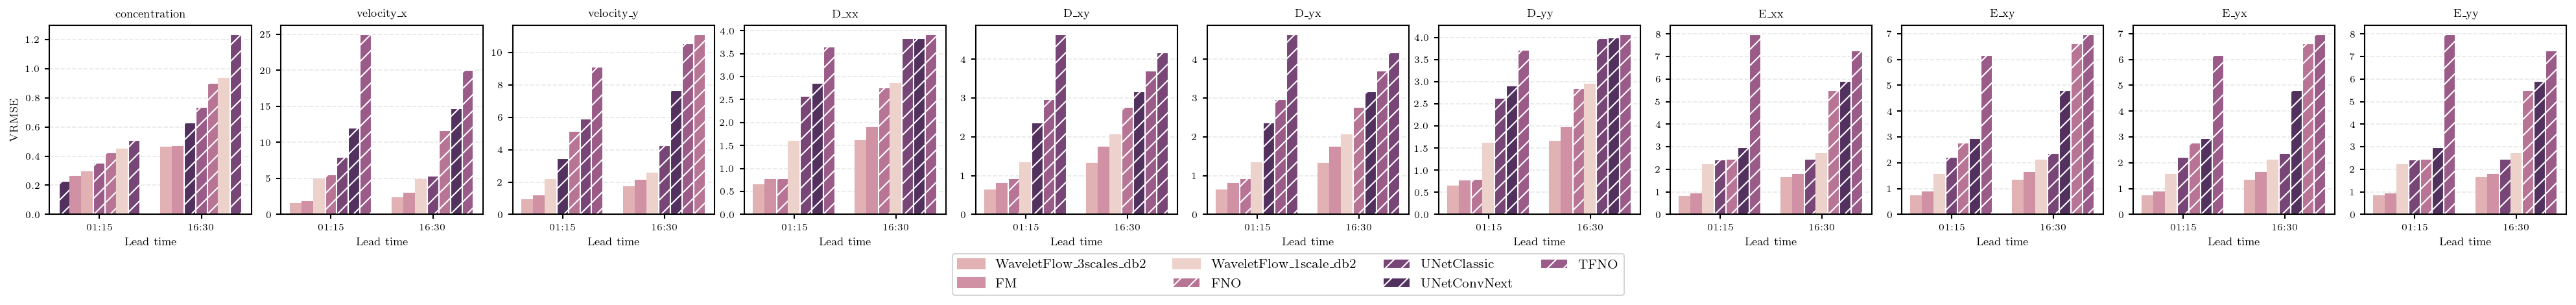

In [8]:
det_lookup = (
    stats_df[["model", "model_type"]]
    .drop_duplicates()
    .set_index("model")["model_type"]
    .to_dict()
)

horizons   = sorted(stats_df["horizon"].unique())
all_models = stats_df["model"].unique().tolist()
n_models   = len(all_models)
bar_width  = 0.8 / n_models

fig, axes = plt.subplots(
    1, n_fields,
    figsize=(2.4 * n_fields, 2.4 + 0.6),
    squeeze=False,
)
axes_flat = axes.flatten()

for ax, field in zip(axes_flat, field_names):
    table = stats_df[stats_df["field"] == field]

    for h_idx, horizon in enumerate(horizons):
        h_table = table[table["horizon"] == horizon]

        # aggregate + sort for this (field, horizon) group
        model_vals = (
            h_table.groupby("model")["vrmse"]
            .apply(aggregate)
            .sort_values()          # shortest bar first (best model)
            .dropna()
        )

        n_present = len(model_vals)
        offsets   = np.linspace(
            -(n_present - 1) / 2,
             (n_present - 1) / 2,
            n_present,
        ) * bar_width

        for offset, (model_name, val) in zip(offsets, model_vals.items()):
            is_det = det_lookup.get(model_name) == "deterministic"
            ax.bar(
                h_idx + offset, val,
                width=bar_width,
                color=model_palette[model_name],
                hatch="//" if is_det else "",
                edgecolor="white" if is_det else model_palette[model_name],
            )

    ax.set_xticks(range(len(horizons)))
    ax.set_xticklabels(horizons)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_ylabel("VRMSE" if ax is axes_flat[0] else "")
    ax.set_title(field)

# ── shared legend sorted by global mean VRMSE ─────────────────────────────
global_order = (
    stats_df.groupby("model")["vrmse"]
    .apply(aggregate)
    .sort_values()
    .index.tolist()
)

legend_handles = [
    mpatches.Patch(
        facecolor=model_palette[m],
        hatch="//" if det_lookup.get(m) == "deterministic" else "",
        edgecolor="white" if det_lookup.get(m) == "deterministic" else model_palette[m],
        label=m,
    )
    for m in global_order
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=4,
    frameon=True,
    fontsize="small",
)

fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.28)
#plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/vrmse_rollout_all_fields.png", dpi=300, bbox_inches='tight') #transparent=True)
plt.show()

# Plot: Aggregated VRMSE at different rollout steps/regimes

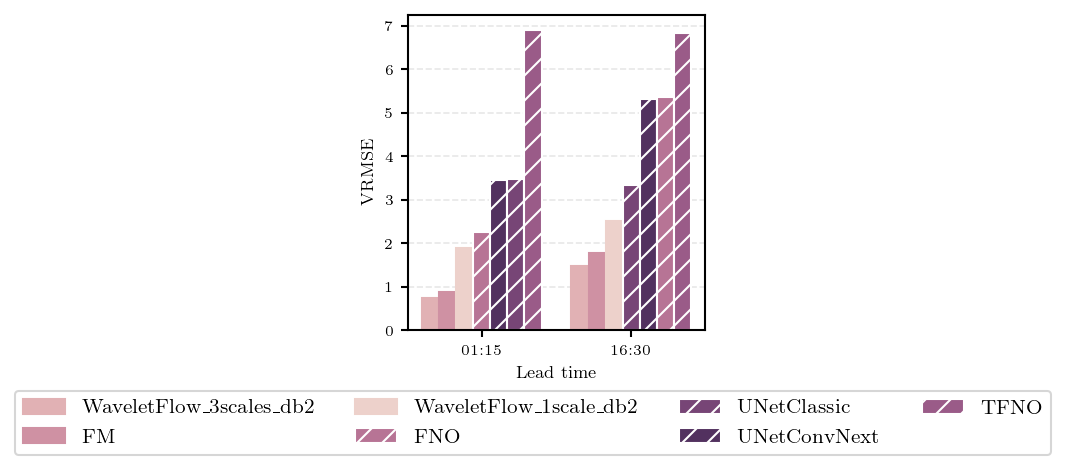

In [9]:
det_lookup = (
    stats_df[["model", "model_type"]]
    .drop_duplicates()
    .set_index("model")["model_type"]
    .to_dict()
)

horizons   = sorted(stats_df["horizon"].unique())
all_models = stats_df["model"].unique().tolist()
n_models   = len(all_models)
bar_width  = 0.8 / n_models

fig, axes = plt.subplots(
    1, 1,
    figsize=(2.4, 2.4 + 0.6),
    squeeze=False,
)
axes_flat = axes.flatten()

for ax, field in zip(axes_flat, field_names):
    table = stats_df

    for h_idx, horizon in enumerate(horizons):
        h_table = table[table["horizon"] == horizon]

        # aggregate + sort for this (field, horizon) group
        model_vals = (
            h_table.groupby("model")["vrmse"]
            .apply(aggregate)
            .sort_values()          # shortest bar first (best model)
            .dropna()
        )

        n_present = len(model_vals)
        offsets   = np.linspace(
            -(n_present - 1) / 2,
             (n_present - 1) / 2,
            n_present,
        ) * bar_width

        for offset, (model_name, val) in zip(offsets, model_vals.items()):
            is_det = det_lookup.get(model_name) == "deterministic"
            ax.bar(
                h_idx + offset, val,
                width=bar_width,
                color=model_palette[model_name],
                hatch="//" if is_det else "",
                edgecolor="white" if is_det else model_palette[model_name],
            )

    ax.set_xticks(range(len(horizons)))
    ax.set_xticklabels(horizons)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_ylabel("VRMSE" if ax is axes_flat[0] else "")
    #ax.set_title(field)

# ── shared legend sorted by global mean VRMSE ─────────────────────────────
global_order = (
    stats_df.groupby("model")["vrmse"]
    .apply(aggregate)
    .sort_values()
    .index.tolist()
)

legend_handles = [
    mpatches.Patch(
        facecolor=model_palette[m],
        hatch="//" if det_lookup.get(m) == "deterministic" else "",
        edgecolor="white" if det_lookup.get(m) == "deterministic" else model_palette[m],
        label=m,
    )
    for m in global_order
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=4,
    frameon=True,
    fontsize="small",
)

fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.28)
#plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/vrmse_rollout_all_fields.png", dpi=300, bbox_inches='tight') #transparent=True)
plt.show()

# Plot: Averaged Power Spectrum RMSE across test trajectories

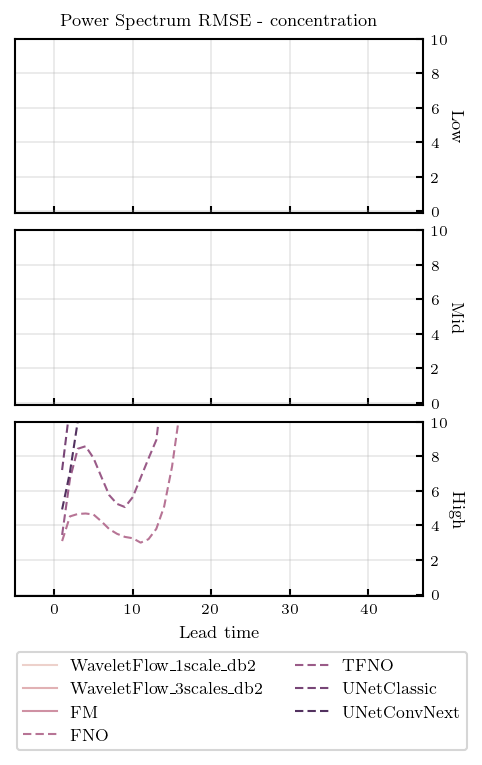

In [10]:
#field = 'concentration'
#table = stats_df[stats_df['field'] == field]
table = stats_df.copy()

fig, axs = plt.subplot_mosaic(
    [[0], [1], [2]],
    figsize=(3.2, 4.8),
    sharex=True,
    sharey=False,
)

dashes = {"generative": (1, 0), "deterministic": (4, 2)}

# Build a model → model_type lookup once
model_type_map = (
    table[["model", "model_type"]]
    .drop_duplicates()
    .set_index("model")["model_type"]
    .to_dict()
)

for i, band in enumerate(["Low", "Mid", "High"]):
    ax = sns.lineplot(
        table,
        x="time",
        y=f"rmse_p_{band.lower()}",
        hue="model",
        style="model_type",
        dashes=dashes,
        estimator=aggregate,
        errorbar=None,
        palette=palette,
        ax=axs[i],
    )
    ax.grid(alpha=0.3)
    ax.set_xlabel("Lead time" if i == 2 else "")
    ax.set_xlim(-5, 47)
    ax.set_ylabel(band)
    ax.set_ylim(-0.1, 10.0)
    ax.tick_params(direction="in")
    ax.yaxis.set_label_position("right")
    ax.yaxis.label.set(rotation=-90, va="center")
    ax.yaxis.tick_right()
    if i == 0:
        ax.set_title(f"Power Spectrum RMSE - {field}")

    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# ── Remove seaborn section headers ───────────────────────────────────────────
clean = [
    (h, l) for h, l in zip(handles, labels)
    if l not in ("model_type", "generative", "deterministic", "model")
]
handles_clean, labels_clean = zip(*clean)

# ── Fix legend handle linestyles to match the plot dashes ────────────────────
for handle, label in zip(handles_clean, labels_clean):
    mtype = model_type_map.get(label)
    if mtype is not None:
        dash_pattern = dashes.get(mtype, (1, 0))
        handle.set_linestyle((0, dash_pattern) if dash_pattern != (1, 0) else "-")

fig.align_labels()
fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.18)
fig.legend(
    handles_clean, labels_clean,
    loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.49, -0.045),
)
#plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/psd_rmse_turbulent_radiative_layer_2D.png", dpi=300, bbox_inches='tight') #transparent=True)
plt.show()

# Spread-Skill Score - Individual Fields

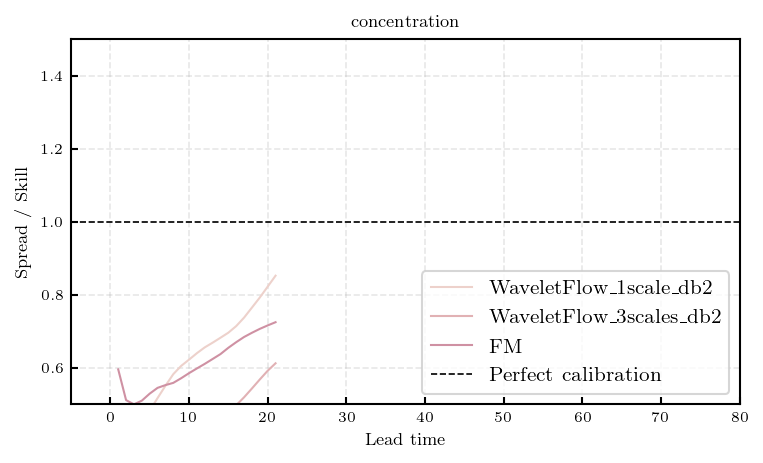

In [11]:
field = 'concentration'
table = stats_df[stats_df['field'] == field].copy()

# deterministic models have no spread/skill — drop them explicitly
table = table[table["model_type"] != "deterministic"]

fig, ax = plt.subplots(figsize=(5, 3))

sns.lineplot(
    table,
    x="time",
    y="spread_skill",
    hue="model",
    estimator=aggregate,
    errorbar=None,
    palette=model_palette,
    ax=ax,
)

# reference line: perfect calibration
ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--", label="Perfect calibration")

ax.get_legend().remove()
ax.grid(linestyle="--", alpha=0.3)
ax.set_xlabel("Lead time")
ax.set_xlim(-5, 80)
ax.set_ylim(0.5, 1.5)
ax.set_ylabel("Spread / Skill")
ax.tick_params(direction="in")
ax.set_title(f"{field}")

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles, labels,
    loc="lower right",
    fontsize="small",
    frameon=True,
    title=None,
)

fig.tight_layout(pad=0.33)
#plt.savefig(f"{outdir}/spread_skill_{field}.png", dpi=300, transparent=True)
plt.show()

# Spread-Skill Score - Average across Fields

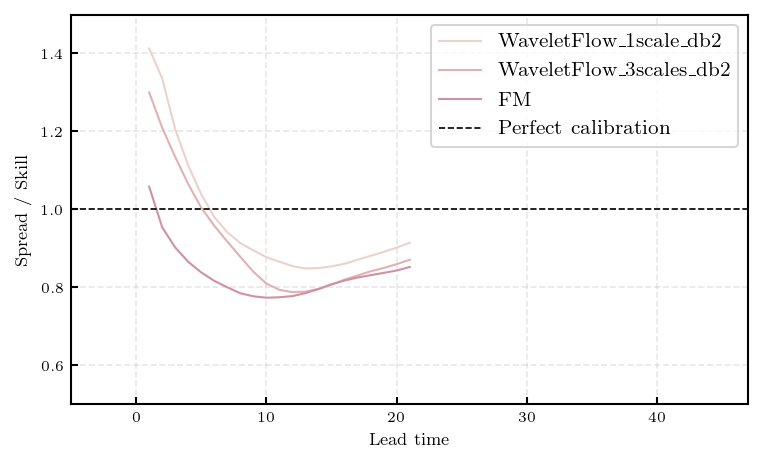

In [12]:
table = stats_df.copy()

# deterministic models have no spread/skill — drop them explicitly
table = table[table["model_type"] != "deterministic"]

fig, ax = plt.subplots(figsize=(5, 3))

sns.lineplot(
    table,
    x="time",
    y="spread_skill",
    hue="model",
    estimator=aggregate,
    errorbar=None,
    palette=model_palette,
    ax=ax,
)

# reference line: perfect calibration
ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--", label="Perfect calibration")

ax.get_legend().remove()
ax.grid(linestyle="--", alpha=0.3)
ax.set_xlabel("Lead time")
ax.set_xlim(-5, 47)
ax.set_ylim(0.5, 1.5)
ax.set_ylabel("Spread / Skill")
ax.tick_params(direction="in")
#ax.set_title(f"{field}")

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles, labels,
    loc="upper right",
    fontsize="small",
    frameon=True,
    title=None,
)

fig.tight_layout(pad=0.33)
#plt.savefig(f"{outdir}/spread_skill_{field}.png", dpi=300, transparent=True)
plt.show()

# Spread-Skill Score - All Fields

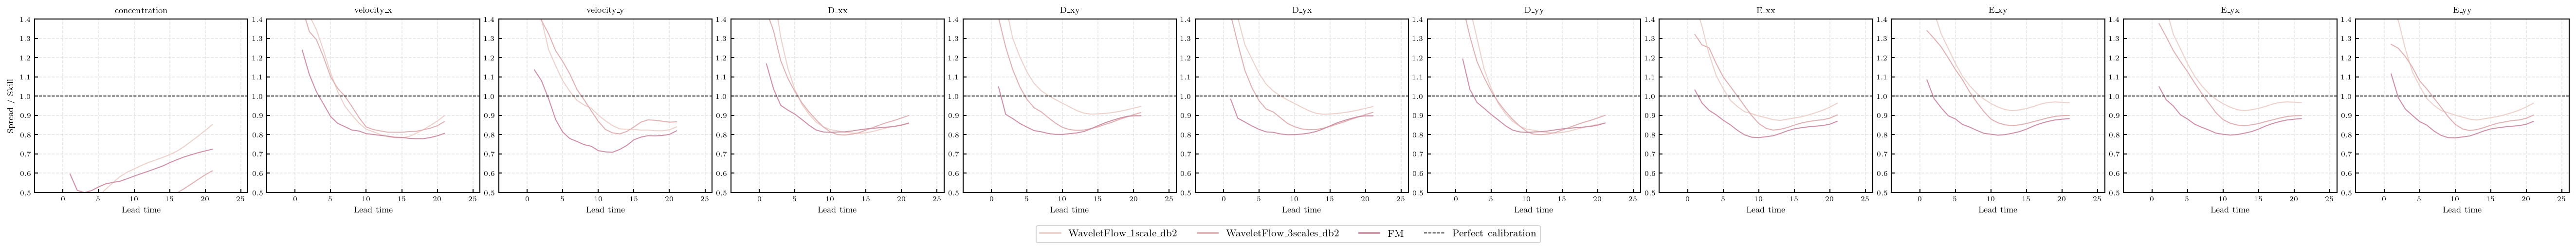

In [13]:
# global model order for the legend (by mean spread/skill, descending —
# closer to 1 is better, so we sort by distance from 1)
global_order = (
    stats_df[stats_df["model_type"] != "deterministic"]
    .groupby("model")["spread_skill"]
    .apply(aggregate)
    .pipe(lambda s: (s - 1).abs().sort_values())   # closest to 1 first
    .index.tolist()
)

fig, axes = plt.subplots(
    1, n_fields,
    figsize=(3.2 * n_fields, 3.0 + 0.6),
    squeeze=False,
)
axes_flat = axes.flatten()

for ax, field in zip(axes_flat, field_names):
    table = (
        stats_df[
            (stats_df["field"] == field) &
            (stats_df["model_type"] != "deterministic")
        ].copy()
    )

    sns.lineplot(
        table,
        x="time",
        y="spread_skill",
        hue="model",
        hue_order=global_order,          # consistent ordering across panels
        estimator=aggregate,
        errorbar=None,
        palette=model_palette, # gen_palette,
        ax=ax,
    )

    # perfect-calibration reference
    ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--")

    ax.get_legend().remove()
    ax.grid(linestyle="--", alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_xlim(stats_df["time"].min() - 5, stats_df["time"].max() + 5)
    ax.set_ylim(0.5, 1.4)
    ax.set_ylabel("Spread / Skill" if ax is axes_flat[0] else "")
    ax.tick_params(direction="in")
    ax.set_title(field)

# ── shared bottom legend ───────────────────────────────────────────────────
legend_handles = [
    mlines.Line2D([], [],
        color=model_palette[m], #gen_palette[m],
        linewidth=1.8,
        label=m,
    )
    for m in global_order
]

# add the reference line entry
legend_handles.append(
    mlines.Line2D([], [],
        color="black", linewidth=0.8, linestyle="--",
        label="Perfect calibration",
    )
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.07),
    ncol=4,
    frameon=True,
    fontsize="small",
)

fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.28)
#plt.savefig(f"{outdir}/spread_skill_all_fields.png", dpi=300, transparent=True)
plt.show()

# CRPS - Individual fields

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

global_order = (
    stats_df.dropna(subset=["crps"])
    .groupby("model")["crps"]
    .apply(aggregate)
    .sort_values()
    .index.tolist()
)

fig, axes = plt.subplots(
    1, n_fields,
    figsize=(3.2 * n_fields, 3.0 + 0.6),
    sharey=False,          # ← independent y-axes per panel
    squeeze=False,
)
axes_flat = axes.flatten()

for ax, field in zip(axes_flat, field_names):
    table = stats_df[stats_df["field"] == field].dropna(subset=["crps"])

    # ── generative ─────────────────────────────────────────────────────────
    gen_table = table[table["model_type"] != "deterministic"]
    if not gen_table.empty:
        sns.lineplot(
            gen_table,
            x="time",
            y="crps",
            hue="model",
            hue_order=[m for m in global_order if m in gen_table["model"].unique()],
            estimator=aggregate,
            errorbar=None,
            palette=model_palette,
            linestyle="-",
            ax=ax,
        )

    # ── deterministic ──────────────────────────────────────────────────────
    det_table = table[table["model_type"] == "deterministic"]
    if not det_table.empty:
        sns.lineplot(
            det_table,
            x="time",
            y="crps",
            hue="model",
            hue_order=[m for m in global_order if m in det_table["model"].unique()],
            estimator=aggregate,
            errorbar=None,
            palette=model_palette,
            linestyle="--",
            ax=ax,
        )

    ax.get_legend().remove()
    ax.grid(linestyle="--", alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_xlim(stats_df["time"].min() - 5, stats_df["time"].max() + 5)
    ax.set_ylim(bottom=0)
    ax.set_ylabel("CRPS" if ax is axes_flat[0] else "")
    ax.tick_params(direction="in")
    ax.set_title(field)

# ── shared legend ──────────────────────────────────────────────────────────
legend_handles = [
    mlines.Line2D([], [],
        color=model_palette[m],
        linewidth=1.8,
        linestyle="--" if det_lookup.get(m) == "deterministic" else "-",
        label=m,
    )
    for m in global_order
]
legend_handles += [
    mlines.Line2D([], [], color="grey", linewidth=1.8, linestyle="-",  label="Generative"),
    mlines.Line2D([], [], color="grey", linewidth=1.8, linestyle="--", label="Deterministic"),
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=4,
    frameon=True,
    fontsize="small",
)

fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.28)
#plt.savefig(f"{outdir}/crps_all_fields.png", dpi=300, transparent=True)
plt.show()

# CRPS - Average across fields

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

global_order = (
    stats_df.dropna(subset=["crps"])
    .groupby("model")["crps"]
    .apply(aggregate)
    .sort_values()
    .index.tolist()
)

fig, axes = plt.subplots(
    1, 1,
    figsize=(3.2 * 1, 3.0 + 0.6),
    sharey=False,          # ← independent y-axes per panel
    squeeze=False,
)
axes_flat = axes.flatten()

for ax, field in zip(axes_flat, field_names):
    #table = stats_df[stats_df["field"] == field].dropna(subset=["crps"])
    table = stats_df.dropna(subset=["crps"])

    # ── generative ─────────────────────────────────────────────────────────
    gen_table = table[table["model_type"] != "deterministic"]
    if not gen_table.empty:
        sns.lineplot(
            gen_table,
            x="time",
            y="crps",
            hue="model",
            hue_order=[m for m in global_order if m in gen_table["model"].unique()],
            estimator=aggregate,
            errorbar=None,
            palette=model_palette,
            linestyle="-",
            ax=ax,
        )

    # ── deterministic ──────────────────────────────────────────────────────
    det_table = table[table["model_type"] == "deterministic"]
    if not det_table.empty:
        sns.lineplot(
            det_table,
            x="time",
            y="crps",
            hue="model",
            hue_order=[m for m in global_order if m in det_table["model"].unique()],
            estimator=aggregate,
            errorbar=None,
            palette=model_palette,
            linestyle="--",
            ax=ax,
        )

    ax.get_legend().remove()
    ax.grid(linestyle="--", alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_xlim(stats_df["time"].min() - 5, stats_df["time"].max() + 5)
    ax.set_ylim(bottom=-0.5, top=0.5)
    ax.set_ylabel("CRPS" if ax is axes_flat[0] else "")
    ax.tick_params(direction="in")
    #ax.set_title(field)

# ── shared legend ──────────────────────────────────────────────────────────
legend_handles = [
    mlines.Line2D([], [],
        color=model_palette[m],
        linewidth=1.8,
        linestyle="--" if det_lookup.get(m) == "deterministic" else "-",
        label=m,
    )
    for m in global_order
]

#legend_handles += [
#    mlines.Line2D([], [], color="grey", linewidth=1.8, linestyle="-",  label="Generative"),
#    mlines.Line2D([], [], color="grey", linewidth=1.8, linestyle="--", label="Deterministic"),
#]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.55, -0.07),
    ncol=2,
    frameon=True,
    fontsize="small",
)

fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.28)
#plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/crps_turbulent_radiative_layer_2D.png", dpi=300, bbox_inches='tight') #, transparent=True)
plt.show()

# PSD

In [19]:
psd_df['model'].unique()

array(['Ground-truth', 'WaveletFlow_1scale_db2',
       'WaveletFlow_3scales_db2', 'FM', 'FNO', 'TFNO', 'UNetClassic',
       'UNetConvNext'], dtype=object)

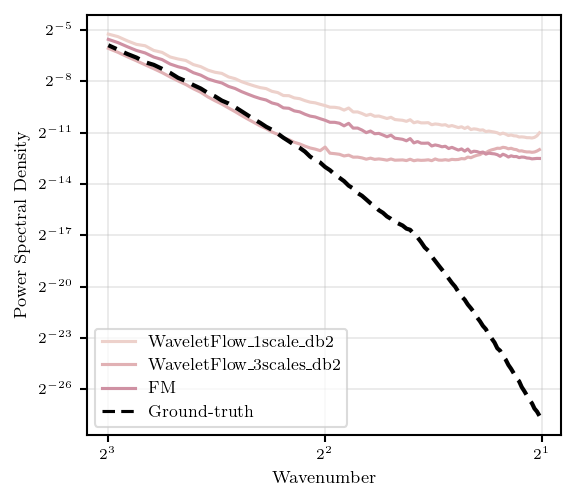

In [14]:
from matplotlib import ticker

field_names = ['all']
gt_label    = "Ground-truth"
all_models  = ['WaveletFlow_1scale_db2', 'WaveletFlow_3scales_db2', 'FM', gt_label]
non_gt_models = [m for m in all_models if m != gt_label]

wl_min, wl_max = 1, 8 #8

table_ds = psd_df[
    psd_df['model'].isin(all_models) &
    (psd_df["band"] != "vhigh") &
    (psd_df["wavelength"] >= wl_min) &
    (psd_df["wavelength"] <= wl_max)
].copy()

fig, axs = plt.subplots(
    1, len(field_names),
    figsize=(4.0 * len(field_names), 3.5),
    sharey=False,
    squeeze=False,
)

for col_idx, field in enumerate(field_names):
    ax = axs[0, col_idx]
    df_field = table_ds

    # ── Non-GT models: solid lines ─────────────────────────────────────────
    sns.lineplot(
        data=df_field[df_field["model"] != gt_label],
        x="wavelength",
        y="psd",
        hue="model",
        hue_order=non_gt_models,
        palette={m: model_palette[m] for m in non_gt_models},
        estimator=aggregate,
        errorbar=None,
        linewidth=1.5,
        ax=ax,
    )

    # ── Ground truth: black dashed, no label (we build the handle manually) ──
    sns.lineplot(
        data=df_field[df_field["model"] == gt_label],
        x="wavelength",
        y="psd",
        color="black",
        linestyle=(0, (4, 2)),
        estimator=aggregate,
        errorbar=None,
        linewidth=2.0,
        label="_nolegend_",   # ← keep seaborn from adding a bad handle
        ax=ax,
    )

    # ── Log-log axes, inverted x ───────────────────────────────────────────
    ax.set_xscale("log", base=2)
    ax.set_yscale("log", base=2)
    ax.invert_xaxis()

    # ── Ticks as 2^n ──────────────────────────────────────────────────────
    wl      = df_field["wavelength"].replace([np.inf], np.nan).dropna()
    exp_min = math.floor(math.log2(wl.min()))
    exp_max = math.ceil(math.log2(wl.max()))
    ticks   = [2 ** e for e in range(exp_min, exp_max + 1)]
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(
        ticker.FuncFormatter(
            lambda v, _: rf"$2^{{{int(round(math.log2(v)))}}}$" if v > 0 else ""
        )
    )
    ax.xaxis.set_minor_locator(ticker.NullLocator())

    # ── Build legend: seaborn handles for models + manual handle for GT ───
    handles, labels = ax.get_legend_handles_labels()
    gt_handle = mlines.Line2D(
        [], [],
        color="black",
        linestyle=(0, (4, 2)),
        linewidth=1.5,
        label=gt_label,
    )
    ax.legend(
        handles + [gt_handle],
        labels  + [gt_label],
        fontsize=8,
        framealpha=0.7,
    )

    #ax.set_title(field)
    ax.set_xlabel("Wavenumber")
    ax.set_ylabel("Power Spectral Density" if col_idx == 0 else "")
    ax.grid(alpha=0.3)

fig.tight_layout()
#plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/psd_turbulent_radiative_layer_2D.png", dpi=300, bbox_inches='tight') #, transparent=True)
#plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/psd_zoom_turbulent_radiative_layer_2D.png", dpi=300, bbox_inches='tight') #, transparent=True)
plt.show()

In [ ]:
psd_df['model'].unique()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import math

#field_names = psd_df["field"].unique().tolist()
field_names =['all']
#field_names = ['density', 'pressure', '']
gt_label    = "Ground-truth"
#all_models  = [m for m in psd_df["model"].unique() if m != gt_label]
all_models  = ['WaveletFlow_1scale_db2', 'WaveletFlow_3scales_db2', 'FM', 'Ground-truth']
#palette     = dict(zip(all_models, sns.color_palette("tab10", n_colors=len(all_models))))
wl_min, wl_max = 1, 8 #128

table = psd_df.copy()
table_ds = table[table['model'].isin(all_models) & 
              (table["band"] != "vhigh") & 
              (table["wavelength"] >= wl_min) & 
              (table["wavelength"] <= wl_max)]

fig, axs = plt.subplots(
    1, len(field_names),
    figsize=(4.0 * len(field_names), 3.5),
    sharey=False,
    squeeze=False,
)

for col_idx, field in enumerate(field_names):
    ax = axs[0, col_idx]
    # Decide to plot per filed or all together (comment out the field filter)
    #df_field = table[table["field"] == field] 
    df_field = table_ds
                     

    # ── non-GT models ──────────────────────────────────────────────────────────
    sns.lineplot(
        data=df_field[(df_field["model"] != gt_label)],
        x="wavelength",
        y="psd",
        hue="model",
        palette=palette,
        estimator=aggregate,
        errorbar=None, #("ci", 95),
        linewidth=1.5,
        ax=ax,
    )

    # ── ground truth — black dashed, no CI ────────────────────────────────────
    sns.lineplot(
        data=df_field[(df_field["model"] == gt_label)],
        x="wavelength",
        y="psd",
        color="black",
        dashes=(4, 2),
        estimator=aggregate,
        errorbar=None,
        linewidth=2.0,
        label=gt_label,
        ax=ax,
    )

    # ── axes: log-log, then invert x (axes-level → invert_xaxis sticks) ───────
    ax.set_xscale("log", base=2)
    ax.set_yscale("log", base=2)
    ax.invert_xaxis()   # large wavelength (low k) on the left

    # ── ticks as 2^n ──────────────────────────────────────────────────────────
    wl      = df_field["wavelength"].replace([np.inf], np.nan).dropna()
    exp_min = math.floor(math.log2(wl.min()))
    exp_max = math.ceil(math.log2(wl.max()))
    ticks   = [2 ** e for e in range(exp_min, exp_max + 1)]
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(
        ticker.FuncFormatter(lambda v, _: rf"$2^{{{int(round(math.log2(v)))}}}$" if v > 0 else "")
    )
    ax.xaxis.set_minor_locator(ticker.NullLocator())

    ax.set_title(field)
    ax.set_xlabel("wavenumber")
    ax.set_ylabel("Power Spectrum Density" if col_idx == 0 else "")

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, fontsize=8, framealpha=0.7)

fig.tight_layout()
plt.show()

# Get Dataset

In [ ]:
well_base_path    = f'{PROJECT_ROOT}/data/datasets'
well_dataset_name = 'turbulent_radiative_layer_2D'

outdir = f'{PROJECT_ROOT}/experiments/{well_dataset_name}/figures'

dataset = get_well_dataset(
    path=well_base_path,
    physics=well_dataset_name,
    split='test',
    steps=-1,          # loads full trajectory
    transform       = ['log_scalars'],   
    augment         = [],
)

meta_field_names = dataset.metadata.field_names
field_names = [item for sublist in meta_field_names.values() for item in sublist]

# Load predictions

In [ ]:
RESULT_DIR = f"{PROJECT_ROOT}/experiments/{well_dataset_name}/results"

model_paths = {
    #"DS-FM"                 : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_data_space_v1.0_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "WaveletFM-1scale"      : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_1scale_db2_v1.0_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "WaveletFM-3scales"     : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_v1.0_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "UNetClassic"           : f'{RESULT_DIR}/UNetClassic_{well_dataset_name}_rollout_traj.pkl',
    "UNetConvNext"          : f'{RESULT_DIR}/UNetConvNext_{well_dataset_name}_rollout_traj.pkl',
    "FNO"                   : f'{RESULT_DIR}/FNO_{well_dataset_name}_rollout_traj.pkl',
}

generative_models = ["WaveletFM-1scale", "WaveletFM-3scales", "DS-FM"]

# model data
rollout_traj = {}
for model, path in model_paths.items():
    with open(path, 'rb') as f:
        rollout_traj[model] = pickle.load(f)

# ground truth data
with open(f'{RESULT_DIR}/ground_truth_{well_dataset_name}_traj.pkl', 'rb') as f:
    truth_traj = pickle.load(f)

# Configuration

In [ ]:
Ti = 4 # number of initial steps to skip (models start from these, so they are not predictions)

#lead_times = [1, 16, 32, 48, 64, 80, 96]

predictions = {
    "DS-FM"             : rollout_traj["DS-FM"],
    "WaveletFM-1scale"  : rollout_traj["WaveletFM-1scale"],    
    "WaveletFM-3scales" : rollout_traj["WaveletFM-3scales"],    
    "UNetClassic"       : rollout_traj["UNetClassic"],        
    #"UNetConvNext"      : rollout_traj["UNetConvNext"],   
    "FNO"               : rollout_traj["FNO"],    
}

palette = sns.cubehelix_palette(len(predictions.keys()), start=8, dark=0.25)
#palette = sns.cubehelix_palette(len(table["model"].unique()), dark=0.25)
palette

# Evaluation Metrics

In [ ]:
aggregate_mode = "mean"

def horizon(t):
    if t <= 31:
        return "01:32"
    elif t <= 63:
        return "33:64"
    else:
        return "65:97"
    
def aggregate(x):
    if "mean" in aggregate_mode:
        return np.mean(x)
    elif "median" in aggregate_mode:
        return np.median(x)

def model_type(model):
    if model in generative_models:
        return "generative"
    return "deterministic"

# Build Stats DataFrame

In [ ]:
df = build_stats_df(
    truth        = truth_traj,  
    predictions  = predictions,
    field_names  = field_names,
    Ti           = Ti,
    lead_times   = None,
    stride       = 1,
)

df["horizon"] = df["time"].apply(horizon)
df["model_type"] = df["model"].apply(model_type)

In [ ]:
df.columns

In [ ]:
summary = (
    df.groupby(["model", "field"])[["vrmse", "rmse_p_low", "rmse_p_mid", "rmse_p_high", "rmse_p_vhigh"]]
    .mean()
    .round(4)
)
print(summary.to_string())

In [ ]:
#summary.style.apply(highlight_min_per_field_horizon, axis=None).format(precision=3)

# Plot: VRMSE at different rollout steps/regimes

In [ ]:
field_names

In [ ]:
%matplotlib inline

field = field_names
table = df[df["field"].isin(field)]

#field = 'density'
#table = df[df["field"] == field]

fig = plt.figure(figsize=(2.4, 2.4))

ax = sns.barplot(
    table,
    x="horizon",
    y="vrmse",
    hue="model",
    estimator=aggregate,
    errorbar=None,
    palette=palette, #sns.cubehelix_palette(5, dark=0.25)[1:],
)

ax.grid()
ax.get_legend().set_title(None)

ax.set_xlabel("Lead time")
ax.set_ylabel("VRMSE")
ax.set_title(field)

fig.tight_layout(pad=0.33)

#plt.savefig(f"{outdir}/vrmse_rollout_{field}.png", dpi=300, transparent=True)
plt.show()

# Plot: Averaged Power Spectrum RMSE across test trajectories

In [ ]:
%matplotlib inline

field = 'density'
table = df[df['field'] == field]

fig, axs = plt.subplot_mosaic(
    [[0], [1], [2]],
    figsize=(3.2, 4.8),
    sharex=True,
    sharey=False,
)

# solid for generative, dashed for deterministic
dashes  = {"generative": (1, 0), "deterministic": (4, 2)}

for i, band in enumerate(["Low", "Mid", "High"]):
    ax = sns.lineplot(
        table,
        x="time",
        y=f"rmse_p_{band.lower()}",
        hue="model",
        style="model_type",
        dashes=dashes,
        estimator=aggregate,
        errorbar=None,
        palette=palette,
        ax=axs[i],
    )
    ax.grid(alpha=0.3)

    ax.set_xlabel("Lead time" if i == 2 else "")
    ax.set_xlim(-5, 101)

    ax.set_ylabel(band)
    ax.set_ylim(-0.1, 1.0)

    ax.tick_params(direction="in")
    ax.yaxis.set_label_position("right")
    ax.yaxis.label.set(rotation=-90, va="center")
    ax.yaxis.tick_right()

    if i == 0:
        ax.set_title("Power Spectrum RMSE")
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# ── Clean up legend: remove the "model_type" section header ───────────────────
clean = [(h, l) for h, l in zip(handles, labels) if l not in ("model_type", "generative", "deterministic", "model")]
handles_clean, labels_clean = zip(*clean)

fig.align_labels()
fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.18)  # make room at the bottom
fig.legend(handles_clean, labels_clean, loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.45, 0.02))
plt.show()

# Plot PSD

In [ ]:
psd_df = build_psd_df(
    truth = truth_traj,
    predictions = predictions,
    field_names = field_names,
    Ti = Ti,
    lead_times = None,
    stride = 1,      
    min_bin_count = 3,   
)

In [ ]:
psd_df

# Plot PSD per field

- https://github.com/francois-rozet/lola/blob/main/lola/plot.py

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import math

#field_names = psd_df["field"].unique().tolist()
#field_names = ['density', 'pressure', '']
gt_label    = "Ground-truth"
all_models  = [m for m in psd_df["model"].unique() if m != gt_label]
#palette     = dict(zip(all_models, sns.color_palette("tab10", n_colors=len(all_models))))
wl_min, wl_max = 1, 8#128


fig, axs = plt.subplots(
    1, len(field_names),
    figsize=(4.0 * len(field_names), 3.5),
    sharey=False,
    squeeze=False,
)

for col_idx, field in enumerate(field_names):
    ax = axs[0, col_idx]
    # Decide to plot per filed or all together (comment out the field filter)
    df_field = psd_df[#(psd_df["field"] == field) & 
                      (psd_df["band"] != "vhigh") &
                      (psd_df["wavelength"] >= wl_min) & 
                      (psd_df["wavelength"] <= wl_max)]

    # ── non-GT models ──────────────────────────────────────────────────────────
    sns.lineplot(
        data=df_field[(df_field["model"] != gt_label)],
        x="wavelength",
        y="psd",
        hue="model",
        palette=palette,
        estimator=aggregate,
        errorbar=None, #("ci", 95),
        linewidth=1.5,
        ax=ax,
    )

    # ── ground truth — black dashed, no CI ────────────────────────────────────
    sns.lineplot(
        data=df_field[(df_field["model"] == gt_label)],
        x="wavelength",
        y="psd",
        color="black",
        dashes=(4, 2),
        estimator=aggregate,
        errorbar=None,
        linewidth=2.0,
        label=gt_label,
        ax=ax,
    )

    # ── axes: log-log, then invert x (axes-level → invert_xaxis sticks) ───────
    ax.set_xscale("log", base=2)
    ax.set_yscale("log", base=2)
    ax.invert_xaxis()   # large wavelength (low k) on the left

    # ── ticks as 2^n ──────────────────────────────────────────────────────────
    wl      = df_field["wavelength"].replace([np.inf], np.nan).dropna()
    exp_min = math.floor(math.log2(wl.min()))
    exp_max = math.ceil(math.log2(wl.max()))
    ticks   = [2 ** e for e in range(exp_min, exp_max + 1)]
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(
        ticker.FuncFormatter(lambda v, _: rf"$2^{{{int(round(math.log2(v)))}}}$" if v > 0 else "")
    )
    ax.xaxis.set_minor_locator(ticker.NullLocator())

    ax.set_title(field)
    ax.set_xlabel("wavenumber")
    ax.set_ylabel("Power Spectrum Density" if col_idx == 0 else "")

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, fontsize=8, framealpha=0.7)

fig.tight_layout()
plt.show()

In [ ]:
fig = plot_psd_seaborn(
    psd_df=psd_df,
    field_names=field_names,
    agg_over=["traj", "ens", "step"],
    gt_label="Ground-truth",
    palette=palette,
    gt_color="black",
    gt_lw=1.5,
    model_lw=1.0,
    ci=None,
    figsize=(4.0, 3.5),
    log_base=2,
)

# PSD Plot from LOLA (select traj + ens + specific step in the trajectory)

In [ ]:
truth_traj.shape

In [ ]:
TRAJ_IDX = 5

x = truth_traj[TRAJ_IDX, ...]
x = rearrange(x, "steps h w c -> c steps h w")
y = predictions['WaveletFM-3scales'][TRAJ_IDX, 0, ...]
#y = predictions['WaveletFM-1scale'][TRAJ_IDX, 0, ...]
#y = predictions['UNetClassic'][TRAJ_IDX, ...]
y = rearrange(y, "steps h w c -> c steps h w")

print(x.shape, y.shape)


plot_psd(
    x = x[:, 64],
    y = y[:, 64],
    fields = field_names,  
)

# Tables 

In [ ]:
table = df[["model", "field", "horizon", "vrmse"]]

table = table.groupby(["model", "field", "horizon"]).agg(aggregate).round(3).reset_index()
table = table.pivot(index=["model", "field"], columns="horizon", values=["vrmse"])
# print(table.to_latex(float_format="%.3f"))
table

In [ ]:
import pandas as pd

def highlight_min_per_field_horizon(df: pd.DataFrame) -> pd.DataFrame:
    styles = pd.DataFrame("", index=df.index, columns=df.columns)

    fields = df.index.get_level_values("field").unique()

    for field, color in zip(fields, palette):
        r, g, b = [int(c * 255) for c in color[:3]]
        css = f"background-color: rgb({r},{g},{b}); color: white; font-weight: bold"

        field_mask = df.index.get_level_values("field") == field
        sub = df.loc[field_mask]           # rows for this field, all models

        for col in df.columns:
            min_idx = sub[col].idxmin()    # (model, field) index of the min
            styles.loc[min_idx, col] = css

    return styles

In [ ]:
table.style.apply(highlight_min_per_field_horizon, axis=None).format(precision=3)